# Sleep Staging with HMMs: Evaluation and Interpretation (NBK 4)

This notebook evaluates the held-out predictions saved by NBK 3. It compares the supervised and unsupervised HMMs across K and feature sets with accuracy, Cohen's kappa, macro-F1, and per-stage results, and tests the differences subject by subject. It then looks inside the models: what each unsupervised state contains, what the learned transitions encode, whether the decoded stages follow the overnight pattern from NBK 2, and how stable Baum–Welch was. Finally, it summarizes the EOG comparison, the ablation, the learning curve, and the label-free check, and shows one decoded night.

---

### Import statements

In [1]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import wilcoxon
from sklearn.metrics import (accuracy_score, cohen_kappa_score, confusion_matrix,
                             precision_recall_fscore_support)
import helpers

---

### Loading predictions

We load the predictions and parameters from NBK 3 and check that they line up epoch by epoch with the features from NBK 1. We also check that every subject belongs to exactly one fold.

In [2]:
predictions = pd.read_csv(os.path.join(helpers.OUT, "predictions.csv.gz"), dtype={"subject": str})
with open(os.path.join(helpers.OUT, "params.json")) as f:
    params = json.load(f)

features = helpers.load_features()
assert (predictions[["recording", "epoch"]] == features[["recording", "epoch"]]).all().all()

assert (predictions.groupby("subject")["fold"].nunique() == 1).all()
Y = {K: helpers.collapse(predictions["stage"], K) for K in helpers.CLASSES}

def parse(column):
    feature_set, K, model = column.split("_", 2)
    return feature_set, int(K[1:]), model

models = [c for c in predictions.columns if c.startswith("EEG") and not c.endswith("_state")]
print(f"{len(predictions):,} epochs, {predictions['subject'].nunique()} subjects, {len(models)} models")

170,252 epochs, 78 subjects, 30 models


The predictions cover all 170,252 epochs from 78 subjects, for 30 models: the supervised and unsupervised HMMs (with both matching rules) for each feature set and K, plus the ablation models.

---

### Accuracy and Cohen's kappa

Accuracy is easy to read but rewards predicting the largest class. Cohen's kappa corrects for this: it measures agreement beyond what is expected by chance from the class frequencies, so a model that always predicts one class scores 0. Macro-F1 averages the F1 score over classes, so rare stages count as much as common ones. We compute each metric over all held-out epochs, and also per subject (mean and standard deviation over the 78 subjects) and per fold. To test whether one model beats another, we compare their per-subject kappas with a Wilcoxon signed-rank test, which pairs the two models on the same subjects.

accuracy  kappa  macro_f1  subject_acc  \
features K model                                                       
EEG      2 supervised            0.904  0.757     0.878        0.907   
           unsupervised          0.750  0.000     0.429        0.760   
           unsupervised_1to1     0.722  0.454     0.706        0.719   
         3 supervised            0.834  0.718     0.807        0.837   
           unsupervised          0.759  0.515     0.545        0.760   
           unsupervised_1to1     0.731  0.584     0.714        0.734   
         4 supervised            0.777  0.671     0.751        0.779   
           unsupervised          0.695  0.528     0.524        0.697   
           unsupervised_1to1     0.654  0.523     0.634        0.659   
         5 supervised            0.732  0.642     0.686        0.737   
           unsupervised          0.701  0.572     0.459        0.701   
           unsupervised_1to1     0.602  0.489     0.569        0.612   
EEG+EOG  2 supervised            0.899  0.743     0.871        0.901   
           unsupervised          0.739  0.242     0.619        0.745   
           unsupervised_1to1     0.746  0.486     0.727        0.742   
         5 supervised            0.741  0.654     0.705        0.745   
           unsupervised          0.705  0.575     0.466        0.704   
           unsupervised_1to1     0.617  0.508     0.595        0.623   

                              subject_acc_sd  subject_kappa  subject_kappa_sd  \
features K model                                                                
EEG      2 supervised                  0.041          0.753             0.091   
           unsupervised                0.089          0.000             0.000   
           unsupervised_1to1           0.063          0.440             0.122   
         3 supervised                  0.053          0.717             0.090   
           unsupervised                0.052          0.505             0.100   
           unsupervised_1to1           0.073          0.585             0.098   
         4 supervised                  0.065          0.666             0.099   
           unsupervised                0.075          0.528             0.094   
           unsupervised_1to1           0.091          0.524             0.117   
         5 supervised                  0.076          0.641             0.101   
           unsupervised                0.068          0.568             0.081   
           unsupervised_1to1           0.109          0.495             0.129   
EEG+EOG  2 supervised                  0.040          0.740             0.090   
           unsupervised                0.080          0.180             0.231   
           unsupervised_1to1           0.058          0.469             0.116   
         5 supervised                  0.073          0.653             0.098   
           unsupervised                0.071          0.570             0.086   
           unsupervised_1to1           0.110          0.510             0.132   

                              fold_kappa_sd  
features K model                             
EEG      2 supervised                 0.021  
           unsupervised               0.000  
           unsupervised_1to1          0.016  
         3 supervised                 0.029  
           unsupervised               0.017  
           unsupervised_1to1          0.034  
         4 supervised                 0.024  
           unsupervised               0.025  
           unsupervised_1to1          0.031  
         5 supervised                 0.039  
           unsupervised               0.009  
           unsupervised_1to1          0.036  
EEG+EOG  2 supervised                 0.026  
           unsupervised               0.230  
           unsupervised_1to1          0.022  
         5 supervised                 0.034  
           unsupervised               0.009  
           unsupervised_1to1          0.035

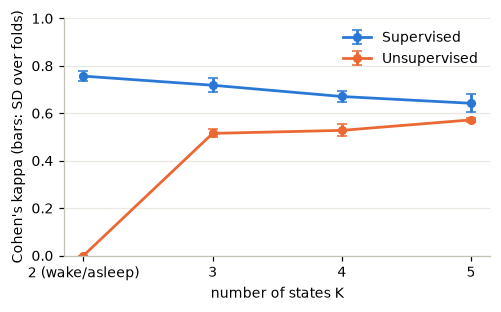

K=2: supervised better for 78 of 78 subjects (Wilcoxon p = 1.7e-14)
K=3: supervised better for 73 of 78 subjects (Wilcoxon p = 7.8e-14)
K=4: supervised better for 68 of 78 subjects (Wilcoxon p = 1.0e-11)
K=5: supervised better for 58 of 78 subjects (Wilcoxon p = 7.7e-07)

Always guessing the largest class: {2: '0.750', 3: '0.598', 4: '0.523', 5: '0.400'}


In [3]:
by_subject = predictions.groupby("subject").indices
by_fold = predictions.groupby("fold").indices

subject_kappa, rows = {}, []
for column in models:
    feature_set, K, model = parse(column)
    y, p = Y[K], predictions[column].to_numpy()
    f1 = precision_recall_fscore_support(y, p, labels=range(K), zero_division=0)[2]
    acc_s = [accuracy_score(y[i], p[i]) for i in by_subject.values()]
    subject_kappa[column] = np.array([cohen_kappa_score(y[i], p[i], labels=range(K)) for i in by_subject.values()])
    kappa_f = [cohen_kappa_score(y[i], p[i], labels=range(K)) for i in by_fold.values()]
    rows.append({"features": feature_set, "K": K, "model": model,
                 "accuracy": accuracy_score(y, p), "kappa": cohen_kappa_score(y, p), "macro_f1": f1.mean(),
                 "subject_acc": np.mean(acc_s), "subject_acc_sd": np.std(acc_s),
                 "subject_kappa": subject_kappa[column].mean(), "subject_kappa_sd": subject_kappa[column].std(),
                 "fold_kappa_sd": np.std(kappa_f)})
summary = pd.DataFrame(rows).set_index(["features", "K", "model"])

main = summary[summary.index.get_level_values("model").isin(["supervised", "unsupervised", "unsupervised_1to1"])]
display(main.round(3))

fig, ax = plt.subplots(figsize=(5, 2.8))
for model in ["supervised", "unsupervised"]:
    s = summary.loc["EEG"].xs(model, level="model")
    ax.errorbar(s.index, s["kappa"], yerr=s["fold_kappa_sd"], color=helpers.MODEL_COLORS[model], marker="o", ms=5,
                capsize=3, label=helpers.MODEL_LABELS[model])
ax.set_xticks([2, 3, 4, 5], ["2 (wake/asleep)", "3", "4", "5"])
ax.set_xlabel("number of states K")
ax.set_ylabel("Cohen's kappa (bars: SD over folds)")
ax.set_ylim(0, 1)
ax.grid(axis="y")
ax.legend()
helpers.save_figure(fig, "kappa_by_K.png")
plt.show()

for K in [2, 3, 4, 5]:
    a, b = subject_kappa[f"EEG_K{K}_supervised"], subject_kappa[f"EEG_K{K}_unsupervised"]
    print(f"K={K}: supervised better for {(a > b).sum()} of {len(a)} subjects "
          f"(Wilcoxon p = {wilcoxon(a, b).pvalue:.1e})")

print("\nAlways guessing the largest class:",
      {K: f"{np.bincount(y).max() / len(y):.3f}" for K, y in Y.items()})

**The supervised HMM beats the unsupervised one at every K.** 

Its kappa falls from 0.757 at K = 2 to 0.718, 0.671, and 0.642 as classes are added. The unsupervised HMM reaches 0.515, 0.528, and 0.572 for K = 3 to 5, so the gap shrinks from 0.20 at K = 3 to 0.07 at K = 5. Subject by subject, the supervised model is better for 73 of 78 subjects at K = 3 and 58 of 78 at K = 5 (Wilcoxon p < 0.001 in both cases). The spread across folds is small (standard deviation 0.04 or less) compared with the spread across subjects (about 0.08 to 0.10).

Accuracy alone would be misleading. Always guessing the largest class gives 75% accuracy at K = 2, which is exactly what the unsupervised K = 2 model achieves with a kappa of 0. At K = 5, the unsupervised model's accuracy (0.701) is close to the supervised model's (0.732), but its macro-F1 is much lower (0.459 vs 0.686) because it misses whole stages, as the next sections show.

---

### Confusion matrices

A confusion matrix shows, for each expert stage (row), how its epochs were classified (columns), as a share of that row. The diagonal is each stage's recall, and the off-diagonal cells show which stages are confused.

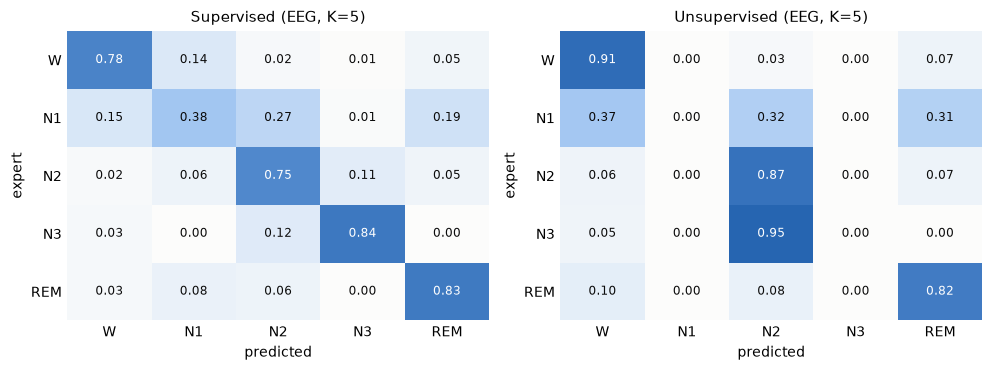

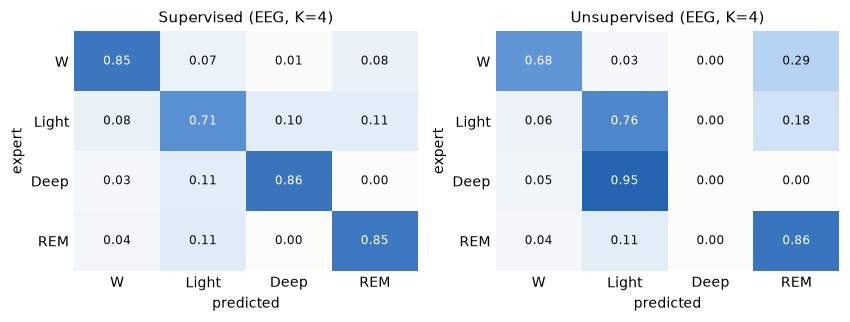

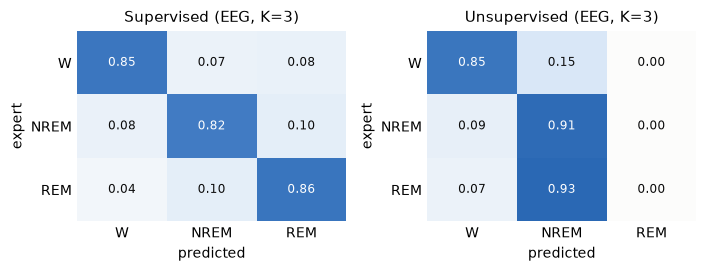

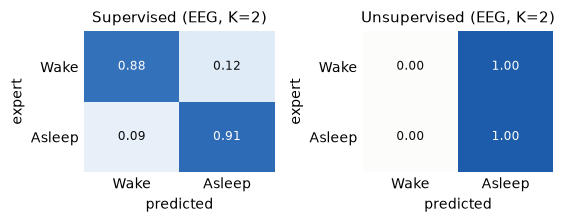

In [4]:
def plot_confusions(feature_set, K, figure_name=None):
    classes = helpers.CLASSES[K]
    fig, axes = plt.subplots(1, 2, figsize=(2.6 + 1.3 * K, 1.2 + 0.45 * K))
    for ax, model in zip(axes, ["supervised", "unsupervised"]):
        cm = confusion_matrix(Y[K], predictions[f"{feature_set}_K{K}_{model}"], labels=range(K))
        helpers.heatmap(ax, cm / cm.sum(axis=1, keepdims=True), classes, classes)
        ax.set_title(f"{helpers.MODEL_LABELS[model]} ({feature_set}, K={K})")
        ax.set_ylabel("expert")
        ax.set_xlabel("predicted")
    fig.tight_layout()
    if figure_name:
        helpers.save_figure(fig, figure_name)
    plt.show()

plot_confusions("EEG", 5, "confusion_K5.png")
plot_confusions("EEG", 4, "confusion_K4.png")
plot_confusions("EEG", 3, "confusion_K3.png")
plot_confusions("EEG", 2, "confusion_K2.png")

At K = 5, the supervised model gets most epochs of wake (0.78), N2 (0.75), N3 (0.84), and REM (0.83) right. N1 is the weak point: only 0.38 is correct, and the rest is spread over N2 (0.27), REM (0.19), and wake (0.15), as expected for a transitional stage. N2 and N3 are confused in both directions (0.11 and 0.12).

**The unsupervised model never predicts N1 or N3.** Its N1 epochs are split almost evenly between wake (0.37), N2 (0.32), and REM (0.31), and 0.95 of N3 is called N2. Merging classes removes some of these problems but creates others: at K = 4 it never predicts deep sleep and calls 0.29 of wake REM, and at K = 3 it never predicts REM, calling 0.93 of REM epochs NREM.

---

### Per-stage precision, recall and F1

Precision is the share of epochs predicted as a stage that really are that stage, recall is the share of a stage's epochs that are found, and F1 combines the two. We compare the supervised model with the unsupervised model under both matching rules at K = 5.

Supervised                     Unsupervised                     \
     precision recall    F1 epochs    precision recall   F1 epochs   
W         0.85   0.78  0.82  42563         0.72   0.91  0.8  42563   
N1        0.39   0.38  0.39  20808         0.00   0.00  0.0  20808   
N2        0.84   0.75  0.79  68156         0.73   0.87  0.8  68156   
N3        0.57   0.84  0.68  12923         0.00   0.00  0.0  12923   
REM       0.69   0.83  0.75  25802         0.61   0.82  0.7  25802   

    Unsup. (one-to-one)                      
              precision recall    F1 epochs  
W                  0.87   0.49  0.63  42563  
N1                 0.24   0.34  0.28  20808  
N2                 0.81   0.61  0.70  68156  
N3                 0.38   0.89  0.54  12923  
REM                0.61   0.82  0.70  25802

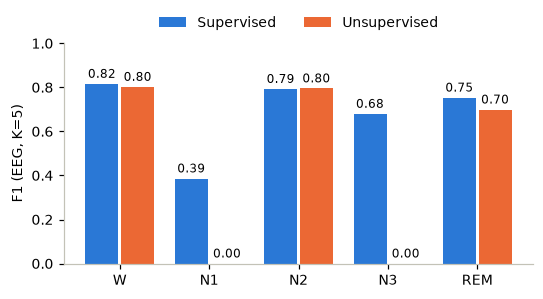

Classes never predicted: {'EEG_K2_unsupervised': ['Wake'], 'EEG_K3_unsupervised': ['REM'], 'EEG_K4_unsupervised': ['Deep'], 'EEG_K5_unsupervised': ['N1', 'N3'], 'EEG+EOG_K5_unsupervised': ['N1', 'N3']}


In [5]:
def per_stage(column):
    _, K, _ = parse(column)
    p, r, f, n = precision_recall_fscore_support(Y[K], predictions[column], labels=range(K), zero_division=0)
    return pd.DataFrame({"precision": p, "recall": r, "F1": f, "epochs": n}, index=helpers.CLASSES[K])

stage_table = pd.concat({helpers.MODEL_LABELS[m]: per_stage(f"EEG_K5_{m}")
                         for m in ["supervised", "unsupervised", "unsupervised_1to1"]}, axis=1)
display(stage_table.round(2))

fig, ax = plt.subplots(figsize=(5.5, 2.6))
x = np.arange(5)
for shift, model in [(-0.2, "supervised"), (0.2, "unsupervised")]:
    bars = ax.bar(x + shift, stage_table[helpers.MODEL_LABELS[model]]["F1"], width=0.37, color=helpers.MODEL_COLORS[model], label=helpers.MODEL_LABELS[model])
    ax.bar_label(bars, fmt="%.2f", fontsize=8, padding=2)
ax.set_xticks(x, helpers.STAGES)
ax.set_ylabel("F1 (EEG, K=5)")
ax.set_ylim(0, 1)
ax.legend(ncol=2, loc="upper center", bbox_to_anchor=(0.5, 1.18))
helpers.save_figure(fig, "per_stage_f1.png")
plt.show()

never = {c: [helpers.CLASSES[parse(c)[1]][k] for k in range(parse(c)[1]) if (predictions[c] != k).all()]
         for c in models if c.endswith("_unsupervised")}
print("Classes never predicted:", {c: n for c, n in never.items() if n})

The supervised model's F1 is 0.82 for wake, 0.79 for N2, 0.75 for REM, 0.68 for N3, and only 0.39 for N1. N3 has high recall (0.84) but low precision (0.57), because many N2 epochs are called N3. The unsupervised model matches the supervised one on wake, N2, and REM (F1 0.80, 0.80, 0.70) but scores 0 on N1 and N3, which explains its low macro-F1.

One-to-one matching does predict every stage, but not well: N3 gets high recall (0.89) with low precision (0.38), N1 reaches an F1 of only 0.28, and wake recall drops to 0.49 because a wake state is forced to stand for another stage. Forcing every stage to appear does not mean the model has found it. Across all unsupervised models, at least one class is never predicted at every K: wake at K = 2, REM at K = 3, deep sleep at K = 4, and N1 and N3 at K = 5.

---

### Interpreting the unsupervised states

To see why stages are missed, we look at the five-state model of fold 0: what share of each state's training epochs belongs to each stage, where each stage's epochs end up, and each state's mean features. We also count how many states are matched to each class in every fold.

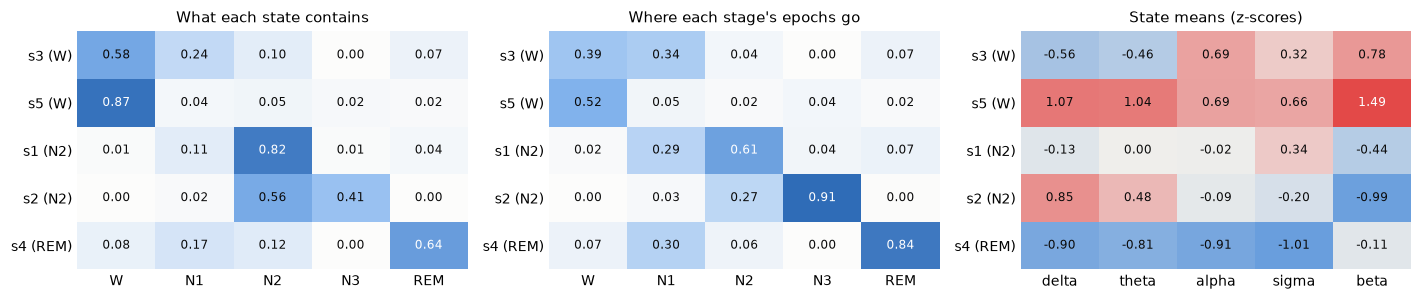

Number of states matched to each class, by fold:
  EEG_K2: {'Wake': '0/0/0/0/0', 'Asleep': '2/2/2/2/2'}
  EEG_K3: {'W': '1/1/1/1/1', 'NREM': '2/2/2/2/2', 'REM': '0/0/0/0/0'}
  EEG_K4: {'W': '1/1/1/1/1', 'Light': '2/2/2/2/2', 'Deep': '0/0/0/0/0', 'REM': '1/1/1/1/1'}
  EEG_K5: {'W': '2/2/2/2/2', 'N1': '0/0/0/0/0', 'N2': '2/2/2/2/2', 'N3': '0/0/0/0/0', 'REM': '1/1/1/1/1'}
  EEG+EOG_K2: {'Wake': '0/1/0/0/1', 'Asleep': '2/1/2/2/1'}
  EEG+EOG_K5: {'W': '2/2/2/2/2', 'N1': '0/0/0/0/0', 'N2': '2/2/2/2/2', 'N3': '0/0/0/0/0', 'REM': '1/1/1/1/1'}
fold 0: one state holds 91% of N3; it is 41% N3 and 56% N2
fold 1: one state holds 89% of N3; it is 38% N3 and 59% N2
fold 2: one state holds 89% of N3; it is 37% N3 and 60% N2
fold 3: one state holds 89% of N3; it is 37% N3 and 60% N2
fold 4: one state holds 88% of N3; it is 37% N3 and 61% N2


In [6]:
def ordered_states(fold):
    u = params["EEG_K5"][fold]["unsupervised"]
    mapping = np.array(u["mapping"])
    order = np.argsort(mapping, kind="stable")
    return u, mapping, order, [f"s{i + 1} ({helpers.STAGES[mapping[i]]})" for i in order]

u, mapping, order, names = ordered_states(0)
overlap = np.array(u["overlap"])[order]

fig, axes = plt.subplots(1, 3, figsize=(13, 2.8))
helpers.heatmap(axes[0], overlap / overlap.sum(axis=1, keepdims=True), names, helpers.STAGES)
axes[0].set_title("What each state contains")
helpers.heatmap(axes[1], overlap / overlap.sum(axis=0, keepdims=True), names, helpers.STAGES)
axes[1].set_title("Where each stage's epochs go")
helpers.heatmap(axes[2], np.array(u["means"])[order], names, helpers.EEG_FEATURES,
                cmap=helpers.DIVERGING, vmin=-1.5, vmax=1.5)
axes[2].set_title("State means (z-scores)")
fig.tight_layout()
helpers.save_figure(fig, "unsupervised_states.png")
plt.show()

rows = []
for name, fold_list in params.items():
    K = int(name.split("_K")[1])
    for k, fold in enumerate(fold_list):
        n = np.bincount(fold["unsupervised"]["mapping"], minlength=K)
        rows.append({"config": name, "fold": k, **dict(zip(helpers.CLASSES[K], n))})
print("Number of states matched to each class, by fold:")
for name in params:
    K = int(name.split("_K")[1])
    table = pd.DataFrame([r for r in rows if r["config"] == name])[helpers.CLASSES[K]]
    print(f"  {name}:", {c: "/".join(table[c].astype(str)) for c in table})

for k in range(helpers.N_FOLDS):
    o = np.array(params["EEG_K5"][k]["unsupervised"]["overlap"])
    s = o[:, 3].argmax()
    print(f"fold {k}: one state holds {o[s, 3] / o[:, 3].sum():.0%} of N3; "
          f"it is {o[s, 3] / o[s].sum():.0%} N3 and {o[s, 2] / o[s].sum():.0%} N2")

The five states are physiologically sensible, but they are not the five clinical stages. Two states are mostly wake: one (87% wake) has high power in every band, and the other (58% wake, 24% N1) has high alpha and beta but low delta. One state is mostly N2 (82%), and one is a REM-like state with low power in every EEG band (64% REM, 17% N1).

**The fifth state is a slow-wave state that holds 91% of all N3 epochs in fold 0**, with high delta and the lowest beta of any state. N3 is rare, though, so the state still contains more N2 than N3 (56% vs 41%), and majority matching names it N2. Baum–Welch therefore finds deep sleep but places its boundary inside N2. N1 never dominates any state, likely because its features lie between wake and REM. The same mapping appears in all five folds (two wake states, two N2 states, one REM state), so this is a stable property of the model, not an unlucky restart. The two wake states match the two groups seen in wake in NBK 2.

---

### Learned transition matrices

We compare the supervised transition matrix, averaged over folds, with the unsupervised one from fold 0, and show the supervised transitions conditional on leaving a stage.

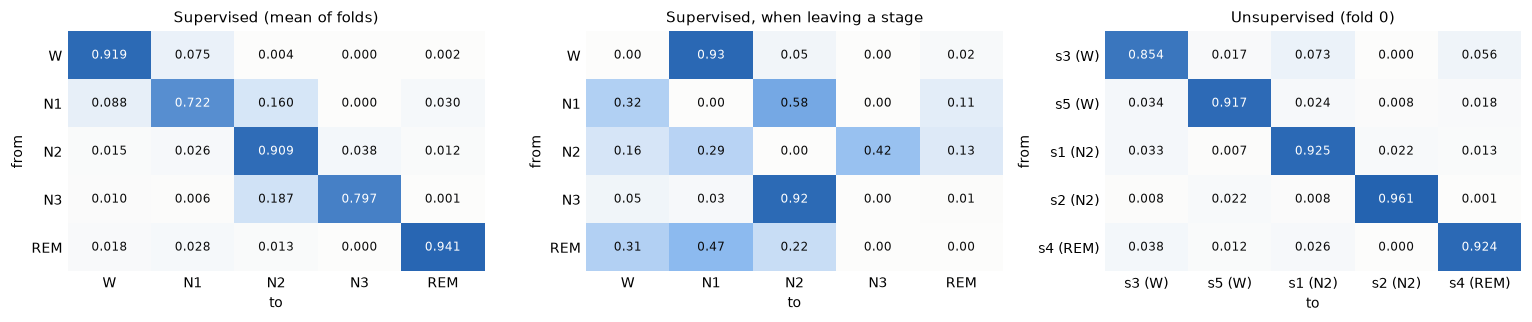

Supervised: P(N3 to N2) = 0.187, P(N3 to REM) = 0.0011, P(N2 to REM) = 0.012
Expected minutes in each stage: {'W': 6.2, 'N1': 1.8, 'N2': 5.5, 'N3': 2.5, 'REM': 8.5}


In [7]:
def leaving(P):
    off = P * (1 - np.eye(len(P)))
    return off / off.sum(axis=1, keepdims=True)

P_sup = np.mean([f["supervised"]["transmat"] for f in params["EEG_K5"]], axis=0)
P_unsup = np.array(u["transmat"])[np.ix_(order, order)]

fig, axes = plt.subplots(1, 3, figsize=(14, 3))
helpers.heatmap(axes[0], P_sup, helpers.STAGES, helpers.STAGES, fmt="{:.3f}")
axes[0].set_title("Supervised (mean of folds)")
helpers.heatmap(axes[1], leaving(P_sup), helpers.STAGES, helpers.STAGES)
axes[1].set_title("Supervised, when leaving a stage")
helpers.heatmap(axes[2], P_unsup, names, names, fmt="{:.3f}")
axes[2].set_title("Unsupervised (fold 0)")
for ax in axes:
    ax.set_ylabel("from")
    ax.set_xlabel("to")
fig.tight_layout()
helpers.save_figure(fig, "transitions.png")
plt.show()

W, N1, N2, N3, REM = range(5)
print(f"Supervised: P(N3 to N2) = {P_sup[N3, N2]:.3f}, P(N3 to REM) = {P_sup[N3, REM]:.4f}, "
      f"P(N2 to REM) = {P_sup[N2, REM]:.3f}")
print("Expected minutes in each stage:",
      {s: round(float(0.5 / (1 - P_sup[i, i])), 1) for i, s in enumerate(helpers.STAGES)})

The supervised matrix encodes the expected sleep cycle: N3 is left for N2 with probability 0.187 per epoch but for REM only 0.001, and N2 leads to REM with probability 0.012. Its expected stage durations (1.8 minutes for N1 to 8.5 for REM) match the experts' in NBK 2, because they are estimated from the same labels.

The unsupervised states are also persistent, with self-transition probabilities between 0.85 and 0.96, so Baum–Welch discovers that sleep comes in long runs without being told. The slow-wave state is the most persistent (0.961).

---

### Decoded N3 and REM across the night

NBK 2 showed that N3 falls and REM rises over the night. A standard HMM has one fixed transition matrix, so any such trend in its predictions must come from the features. We compare the share of N3 and REM among sleep epochs in each third of the sleep period for the experts and both models.

N1    N2    N3   REM
             epoch                         
Expert       early   16.7  53.2  18.2  12.0
             middle  12.5  55.6   8.6  23.2
             late    20.0  51.1   3.8  25.1
Supervised   early   15.4  45.6  26.7  12.2
             middle  10.8  52.0  12.5  24.6
             late    18.9  42.6   5.3  33.2
Unsupervised early    0.0  82.8   0.0  17.2
             middle   0.0  71.7   0.0  28.3
             late     0.0  57.2   0.0  42.8

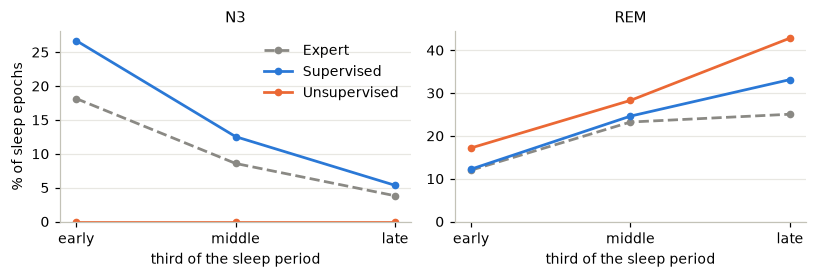

In [8]:
position = helpers.night_position(predictions)
third = pd.cut(position, [0, 1/3, 2/3, 1], include_lowest=True, labels=["early", "middle", "late"])

sources = {"Expert": Y[5], "Supervised": predictions["EEG_K5_supervised"],
           "Unsupervised": predictions["EEG_K5_unsupervised"]}
table = {}
for name, codes in sources.items():
    codes = pd.Series(np.asarray(codes), index=predictions.index)
    keep = third.notna() & (codes != 0)                      # decoded as sleep
    shares = pd.crosstab(third[keep], codes[keep], normalize="index") * 100
    shares = shares.reindex(columns=range(1, 5), fill_value=0)
    shares.columns = helpers.STAGES[1:]
    table[name] = shares
overnight = pd.concat(table)
display(overnight.round(1))

fig, axes = plt.subplots(1, 2, figsize=(7.5, 2.6), sharex=True)
style = {"Expert": (helpers.GRAY, "--"), "Supervised": (helpers.BLUE, "-"), "Unsupervised": (helpers.ORANGE, "-")}
for ax, stage in zip(axes, ["N3", "REM"]):
    for name, (color, dash) in style.items():
        ax.plot(["early", "middle", "late"], table[name][stage], color=color, ls=dash, marker="o", ms=4, label=name)
    ax.set_title(stage)
    ax.set_ylim(0)
    ax.grid(axis="y")
axes[0].set_ylabel("% of sleep epochs")
axes[0].legend()
axes[0].set_xlabel("third of the sleep period")
axes[1].set_xlabel("third of the sleep period")
fig.tight_layout()
helpers.save_figure(fig, "overnight_decoded.png")
plt.show()

**The supervised model reproduces the trend**: its N3 falls from 26.7% to 12.5% and 5.3%, and its REM rises from 12.2% to 24.6% and 33.2%. It overpredicts both, especially N3 early in the night and REM late in the night, compared with the experts' 18.2% to 3.8% for N3 and 12.0% to 25.1% for REM. The unsupervised model follows the REM trend but overpredicts it strongly, reaching 42.8% in the last third, and never predicts N3. Since the transitions are the same all night, the trend comes entirely from how the EEG changes between early and late sleep.

---

### Convergence across restarts

For each configuration we summarize the 50 Baum–Welch runs (10 restarts in each of 5 folds): the median and maximum number of iterations, how many reached the 500-iteration cap, how often the k-means start was selected, and the average gap in final log-likelihood between the best and worst restart. We also compare the held-out log-likelihood per epoch of the supervised and unsupervised models.

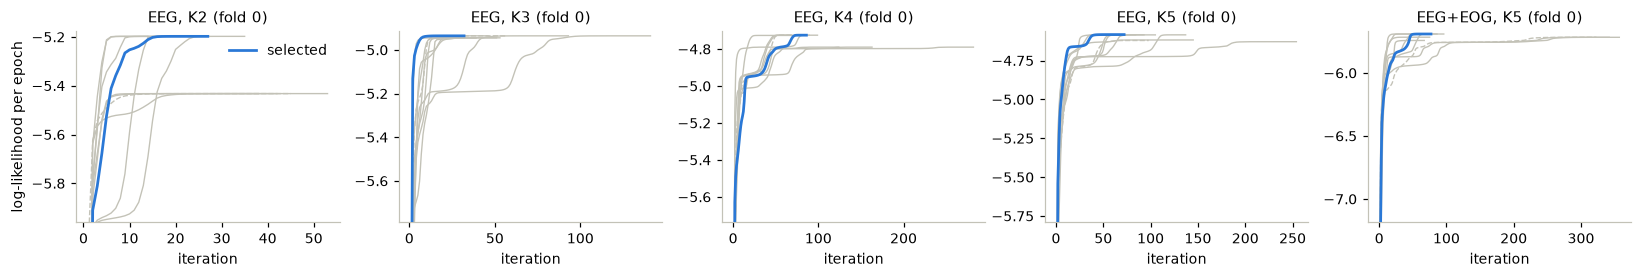

,restarts,median_iterations,max_iterations,hit_cap,kmeans_selected,best_minus_worst,mean_seconds,test_ll_supervised,test_ll_unsupervised
config,,,,,,,,,
EEG_K2,50,29.0,53,0,1,0.137,20.189,-5.334,-5.208
EEG_K3,50,55.0,208,0,0,0.013,50.216,-5.102,-4.955
EEG_K4,50,88.0,282,0,0,0.043,44.411,-4.947,-4.766
EEG_K5,50,112.0,363,0,0,0.023,77.058,-4.849,-4.636
EEG+EOG_K2,50,25.0,40,0,0,0.000,9.643,-6.762,-6.452
EEG+EOG_K5,50,110.5,357,0,0,0.045,77.682,-6.035,-5.762


In [9]:
names_shown = ["EEG_K2", "EEG_K3", "EEG_K4", "EEG_K5", "EEG+EOG_K5"]
fig, axes = plt.subplots(1, 5, figsize=(15, 2.6))
for ax, name in zip(axes, names_shown):
    fold = params[name][0]["unsupervised"]
    for r, run in enumerate(fold["runs"]):
        chosen = r == fold["best"]
        ax.plot(range(1, len(run["trace"]) + 1), run["trace"], color=helpers.BLUE if chosen else "#c3c2b7",
                lw=1.8 if chosen else 0.9, zorder=3 if chosen else 2, ls="--" if run["kmeans"] else "-",
                label="selected" if chosen else None)
    ax.set_title(f"{name.replace('_', ', ')} (fold 0)")
    ax.set_xlabel("iteration")
    low = min(run["trace"][min(2, len(run["trace"]) - 1)] for run in fold["runs"])
    ax.set_ylim(low, max(run["final"] for run in fold["runs"]) + 0.02)
axes[0].set_ylabel("log-likelihood per epoch")
axes[0].legend()
fig.tight_layout()
helpers.save_figure(fig, "convergence.png")
plt.show()

rows = []
for name, fold_list in params.items():
    runs = [r for f in fold_list for r in f["unsupervised"]["runs"]]
    finals = [[r["final"] for r in f["unsupervised"]["runs"]] for f in fold_list]
    rows.append({"config": name, "restarts": len(runs),
                 "median_iterations": np.median([len(r["trace"]) for r in runs]),
                 "max_iterations": max(len(r["trace"]) for r in runs),
                 "hit_cap": sum(r["hit_cap"] for r in runs),
                 "kmeans_selected": sum(f["unsupervised"]["best"] == 0 for f in fold_list),
                 "best_minus_worst": np.mean([max(x) - min(x) for x in finals]),
                 "mean_seconds": np.mean([r["seconds"] for r in runs]),
                 "test_ll_supervised": np.mean([f["supervised"]["test_ll"] for f in fold_list]),
                 "test_ll_unsupervised": np.mean([f["unsupervised"]["test_ll"] for f in fold_list])})
convergence = pd.DataFrame(rows).set_index("config")
convergence.round(3)

**Training was stable.** No run reached the 500-iteration cap; the median run took 25 to 112 iterations and the longest 363, with more states needing more iterations. Restarts still matter: the gap between the best and worst restart averages 0.01 to 0.14 nats per epoch, and the k-means start gave the best restart in only 1 of the 30 fold-level fits. At K = 2, the restarts in fold 0 end at two different values, so EM has more than one local maximum and the restarts are needed to find the better one.

**The unsupervised model has a higher held-out log-likelihood than the supervised one in every configuration** (for example, −4.636 vs −4.849 per epoch at K = 5), yet it agrees less with the experts. It is the better model of the features, but the partition that best explains the EEG is not the experts' partition. This suggests that labels help mainly by pushing the model toward the boundaries the experts use.

---

### Effect of adding EOG

We compare each model with and without the two EOG features at K = 2 and K = 5, overall, per stage, and subject by subject.

accuracy  kappa  macro_f1  subject_kappa
K model        features                                          
2 supervised   EEG          0.904  0.757     0.878          0.753
               EEG+EOG      0.899  0.743     0.871          0.740
  unsupervised EEG          0.750  0.000     0.429          0.000
               EEG+EOG      0.739  0.242     0.619          0.180
5 supervised   EEG          0.732  0.642     0.686          0.641
               EEG+EOG      0.741  0.654     0.705          0.653
  unsupervised EEG          0.701  0.572     0.459          0.568
               EEG+EOG      0.705  0.575     0.466          0.570

Supervised                                           Unsupervised  \
        F1 EEG F1 EEG+EOG recall change precision change       F1 EEG   
W         0.82       0.81         -0.02             0.02          0.8   
N1        0.39       0.43          0.11            -0.01          0.0   
N2        0.79       0.80          0.02             0.00          0.8   
N3        0.68       0.69         -0.00             0.02          0.0   
REM       0.75       0.79         -0.03             0.09          0.7   

                                               
    F1 EEG+EOG recall change precision change  
W         0.78          0.03            -0.05  
N1        0.00          0.00             0.00  
N2        0.79          0.00            -0.00  
N3        0.00          0.00             0.00  
REM       0.75         -0.03             0.11

Supervised: EOG helps 51 of 78 subjects (Wilcoxon p = 1.1e-02)
Unsupervised: EOG helps 44 of 78 subjects (Wilcoxon p = 3.7e-01)


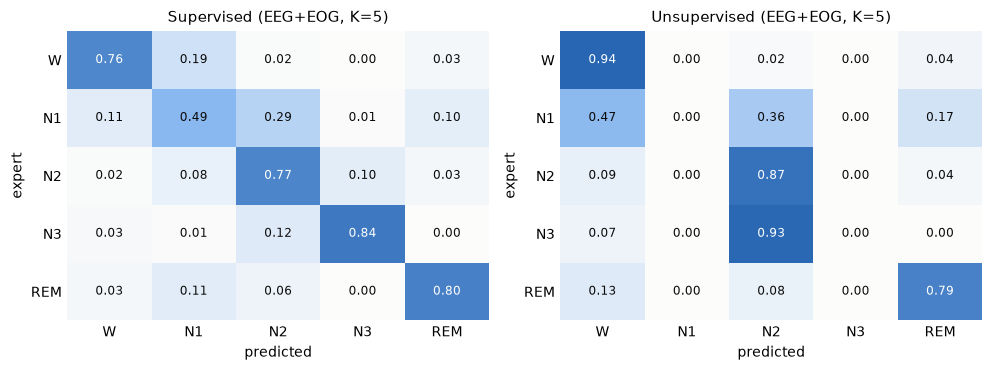

In [10]:
rows = summary.reset_index()
rows = rows[rows["K"].isin([2, 5]) & rows["model"].isin(["supervised", "unsupervised"])]
display(rows.sort_values(["K", "model", "features"]).set_index(["K", "model", "features"])
        [["accuracy", "kappa", "macro_f1", "subject_kappa"]].round(3))

eog = {}
for model in ["supervised", "unsupervised"]:
    before, after = per_stage(f"EEG_K5_{model}"), per_stage(f"EEG+EOG_K5_{model}")
    eog[helpers.MODEL_LABELS[model]] = pd.DataFrame({"F1 EEG": before["F1"], "F1 EEG+EOG": after["F1"],
                                       "recall change": after["recall"] - before["recall"],
                                       "precision change": after["precision"] - before["precision"]})
display(pd.concat(eog, axis=1).round(2))

for model in ["supervised", "unsupervised"]:
    a, b = subject_kappa[f"EEG+EOG_K5_{model}"], subject_kappa[f"EEG_K5_{model}"]
    print(f"{helpers.MODEL_LABELS[model]}: EOG helps {(a > b).sum()} of {len(a)} subjects (Wilcoxon p = {wilcoxon(a, b).pvalue:.1e})")
plot_confusions("EEG+EOG", 5, "confusion_K5_eog.png")

EOG helps the supervised model a little at K = 5: kappa rises from 0.642 to 0.654, and it improves for 51 of 78 subjects (Wilcoxon p = 0.011). The gain is where we expected: N1 recall rises from 0.38 to 0.49 and REM precision from 0.69 to 0.78, so fewer N1 epochs are mistaken for REM. At K = 2, EOG slightly lowers the supervised kappa (0.757 to 0.743).

For the unsupervised model, EOG makes no clear difference at K = 5 (0.572 to 0.575; better for 44 of 78 subjects, p = 0.37), and it still never predicts N1 or N3. NBK 2 showed that the fast EOG feature is far from Gaussian in N1, which may be why the unsupervised model cannot use it to form an N1 state.

---

### Ablation results

We collect the kappas of the simpler models from NBK 3 next to the full HMMs, and test the K = 5 differences subject by subject.

In [11]:
ablation = summary.loc["EEG"]["kappa"].unstack("model")[
    ["supervised", "diagonal", "classifier", "unsupervised", "gmm"]].rename(columns=helpers.MODEL_LABELS)
display(ablation.round(3))

for a, b in [("supervised", "classifier"), ("unsupervised", "gmm")]:
    x, z = subject_kappa[f"EEG_K5_{a}"], subject_kappa[f"EEG_K5_{b}"]
    print(f"K=5: {helpers.MODEL_LABELS[a]} HMM beats {helpers.MODEL_LABELS[b]} for {(x > z).sum()} of {len(x)} subjects "
          f"(Wilcoxon p = {wilcoxon(x, z).pvalue:.1e})")

model,Supervised,"Supervised, diagonal cov.","Supervised, no transitions",Unsupervised,GMM (no transitions)
K,,,,,
2,0.757,0.679,0.677,0.000,0.647
3,0.718,0.612,0.629,0.515,0.484
4,0.671,0.576,0.609,0.528,0.427
5,0.642,0.551,0.584,0.572,0.456


K=5: Supervised HMM beats Supervised, no transitions for 68 of 78 subjects (Wilcoxon p = 6.7e-13)
K=5: Unsupervised HMM beats GMM (no transitions) for 78 of 78 subjects (Wilcoxon p = 1.7e-14)


**Transitions help the supervised model at every K, and the unsupervised model at K = 3 to 5.** At K = 5 the supervised HMM beats the same model without transitions for 68 of 78 subjects, and the unsupervised HMM beats the Gaussian mixture for all 78 subjects (both p < 0.001). Diagonal covariances lower the supervised kappa at every K (0.551 vs 0.642 at K = 5), so the correlations between features matter.

The exception is unsupervised K = 2, where the Gaussian mixture (0.647) far outperforms the HMM (0). The mixture's two components line up with wake and sleep much better than the HMM's two states do.

---

### Learning curve

We plot the held-out kappa against the number of training subjects from NBK 3, with the standard deviation over folds, and list the fitting times.

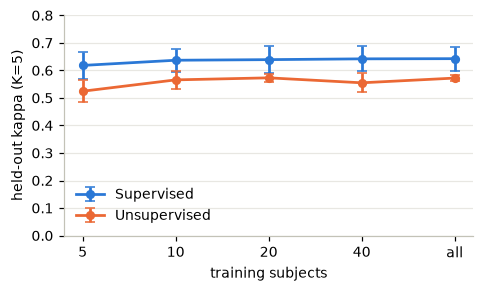

,epochs,supervised,unsupervised,supervised_seconds,unsupervised_seconds
subjects,,,,,
5,11095.2,0.618,0.524,0.004,5.663
10,21595.0,0.637,0.566,0.003,9.751
20,43044.4,0.639,0.573,0.009,27.526
40,87410.8,0.642,0.555,0.014,58.195
all,136201.6,0.643,0.572,0.021,108.312


In [12]:
curve = pd.read_csv(os.path.join(helpers.OUT, "learning_curve.csv"))
curve["subjects"] = curve["subjects"].astype(str)
grouped = curve.groupby("subjects", sort=False)

fig, ax = plt.subplots(figsize=(4.8, 2.6))
for model in ["supervised", "unsupervised"]:
    ax.errorbar(grouped.size().index, grouped[model].mean(), yerr=grouped[model].std(), color=helpers.MODEL_COLORS[model],
                marker="o", ms=5, capsize=3, label=helpers.MODEL_LABELS[model])
ax.set_xlabel("training subjects")
ax.set_ylabel("held-out kappa (K=5)")
ax.set_ylim(0, 0.8)
ax.grid(axis="y")
ax.legend()
helpers.save_figure(fig, "learning_curve.png")
plt.show()
grouped[["epochs", "supervised", "unsupervised", "supervised_seconds", "unsupervised_seconds"]].mean().round(3)

Both curves are nearly flat after 10 subjects. The supervised kappa rises from 0.618 with 5 subjects to 0.643 with all of them, and the unsupervised kappa stays between 0.555 and 0.573 from 10 subjects on. This suggests that more data of the same kind would change little, and that the remaining errors come mostly from the model and features. The cost of training grows with the data for the unsupervised model (about 6 seconds with 5 subjects and 108 seconds with all), while the supervised fit stays at about 0.02 seconds.

---

### Label-free window

We compare the K = 5 results on the main window with those on the label-free window from NBK 1, both overall and on the epochs the two windows share.

In [13]:
sensitivity = pd.read_csv(os.path.join(helpers.OUT, "sensitivity_lights_off.csv")).set_index("model")
sensitivity.round(3)

,main window,label-free window,"main, shared epochs","label-free, shared epochs"
model,,,,
supervised,0.642,0.668,0.639,0.634
unsupervised,0.572,0.604,0.556,0.559


On the shared epochs, the kappas are almost identical: 0.639 vs 0.634 for the supervised model and 0.556 vs 0.559 for the unsupervised model. The higher kappas on the label-free window as a whole (0.668 and 0.604) likely come from the different epochs it contains. **Using the expert labels to set the window does not change the comparison between the models.**

---

### Example decoded hypnograms

We show the expert, supervised, and unsupervised hypnograms for the held-out night whose supervised kappa is closest to the median, and list the longest stretches where the supervised model disagrees with the experts.

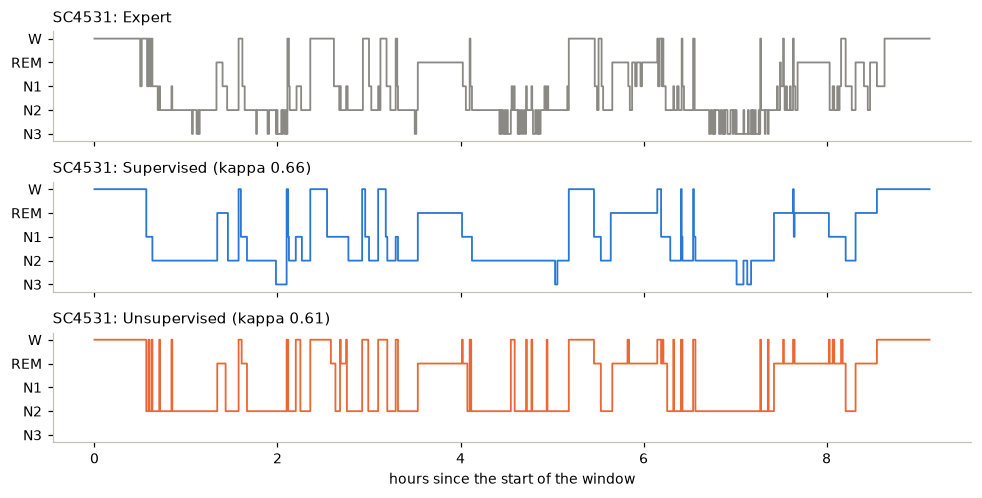

8.0 min: expert N2, model REM
7.0 min: expert N1, model N2
5.0 min: expert N1, model W


In [14]:
night_kappa = {r: cohen_kappa_score(Y[5][i], predictions["EEG_K5_supervised"].to_numpy()[i])
               for r, i in predictions.groupby("recording").indices.items()}
night_kappa = pd.Series(night_kappa)
recording = (night_kappa - night_kappa.median()).abs().idxmin()
g = predictions[predictions["recording"] == recording]

HEIGHT = np.array([4, 2, 1, 0, 3])
hours = (g["epoch"] - g["epoch"].min()) * helpers.EPOCH_SEC / 3600
rows = [("Expert", Y[5][g.index], helpers.GRAY), ("Supervised", g["EEG_K5_supervised"], helpers.BLUE),
        ("Unsupervised", g["EEG_K5_unsupervised"], helpers.ORANGE)]
fig, axes = plt.subplots(3, 1, figsize=(9, 4.6), sharex=True)
for ax, (name, codes, color) in zip(axes, rows):
    codes = np.asarray(codes)
    ax.step(hours, HEIGHT[codes], where="post", color=color, lw=1.2)
    ax.set_yticks([4, 3, 2, 1, 0], ["W", "REM", "N1", "N2", "N3"])
    ax.set_ylim(-0.3, 4.3)
    extra = "" if name == "Expert" else f" (kappa {cohen_kappa_score(Y[5][g.index], codes):.2f})"
    ax.set_title(f"{recording}: {name}{extra}", loc="left")
axes[-1].set_xlabel("hours since the start of the window")
fig.tight_layout()
helpers.save_figure(fig, "example_decoded.png")
plt.show()

wrong = (Y[5][g.index] != g["EEG_K5_supervised"].to_numpy()).astype(int)
edges = np.flatnonzero(np.diff(np.r_[0, wrong, 0]))
runs = sorted(zip(edges[::2], edges[1::2]), key=lambda r: r[0] - r[1])[:3]
for a, b in runs:
    expert = pd.Series(Y[5][g.index][a:b]).mode()[0]
    model = g["EEG_K5_supervised"].iloc[a:b].mode()[0]
    print(f"{(b - a) / 2:.1f} min: expert {helpers.STAGES[expert]}, model {helpers.STAGES[model]}")

The median night is SC4531, with a supervised kappa of 0.66 (night kappas range from 0.31 to 0.86). Both models follow the broad structure of the night and, thanks to the transitions, produce long, clean stage runs instead of flickering between stages. The unsupervised model labels the slow-wave periods as N2 and has no N1. The longest supervised errors are an 8-minute stretch of expert N2 decoded as REM and 7- and 5-minute stretches of expert N1 decoded as N2 and wake, the same confusions seen in the confusion matrix.

---

### Saving outputs

We save the main tables to `results/` and the figures to `figures/`. The key figures are `kappa_by_K.png` (main comparison), `confusion_K5.png` (which stages are confused), `unsupervised_states.png` (what the unsupervised model finds), and `overnight_decoded.png` (the overnight trend).

In [15]:
tables = {"summary": summary, "per_stage_K5": stage_table, "ablation": ablation, "convergence": convergence,
          "overnight": overnight}
for name, table in tables.items():
    table.round(4).to_csv(os.path.join(helpers.OUT, f"{name}.csv"))
print("Tables:", sorted(tables))
print("Figures:", sorted(f for f in os.listdir(helpers.FIG) if f.endswith(".png")))

Tables: ['ablation', 'convergence', 'overnight', 'per_stage_K5', 'summary']
Figures: ['confusion_K2.png', 'confusion_K3.png', 'confusion_K4.png', 'confusion_K5.png', 'confusion_K5_eog.png', 'convergence.png', 'example_decoded.png', 'example_hypnogram.png', 'expert_transitions.png', 'features_by_stage.png', 'gaussian_check.png', 'kappa_by_K.png', 'learning_curve.png', 'overnight_decoded.png', 'overnight_expert.png', 'per_stage_f1.png', 'stage_distribution.png', 'transitions.png', 'unsupervised_states.png']


We save five tables (`summary`, `per_stage_K5`, `ablation`, `convergence`, and `overnight`) and the figures from this notebook.

---